# Probability and Statistics Lab 2: random variables, and limit theorems

## General comments and instructions

-   The report must be prepared as *jupyter notebook along with compiled PDF*.
-   For each task, include
    -   the statistics obtained (like sample mean or anything else you use to complete the task) as well as histograms etc to illustrate your findings;
    -   justification of your solution (e.g. refer to the corresponding theorems from probability theory); whenever applicable, provide LaTeX formulas and derivations.
    -   conclusions (e.g. how reliable your answer is, does it agree with common sense expectations etc.).
-   Not complying with these instructions may result in point deduction.


### Work breakdown:

- NameSurname1: ...
- NameSurname2: ...
- NameSurname3: ...


A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list. We keep it for reproducible calculations.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ecdf, norm, poisson, binom, gamma

team_id: int = 33

random.seed(team_id)
np.random.seed(team_id)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
z975 = norm.ppf(0.975)      # 1.95996..., two-sided 95% quantile
z95 = norm.ppf(0.95)        # 1.64485..., one-sided 95% quantile

## Task 1. Hamming codes


In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1 \\
0 & 1 & 1 & 0 & 0 & 1 & 1 \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*


Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


In [2]:
G = np.array([[1, 1, 1, 0, 0, 0, 0],
              [1, 0, 0, 1, 1, 0, 0],
              [0, 1, 0, 1, 0, 1, 0],
              [1, 1, 0, 1, 0, 0, 1]])
Ht = np.array([[1, 0, 1, 0, 1, 0, 1],
               [0, 1, 1, 0, 0, 1, 1],
               [0, 0, 0, 1, 1, 1, 1]])
H = Ht.T                                    # 7 x 3
print("G H mod 2 =\n", (G @ H) % 2)

p = (2 + team_id/4) / 100
print("p =", p)

def transmit(N, p):
    """Encode N random 4-bit messages, send them through the noisy channel, decode by syndrome."""
    m = np.random.randint(0, 2, size=(N, 4))
    c = (m @ G) % 2
    flips = (np.random.random((N, 7)) < p).astype(int)
    r = (c + flips) % 2
    z = (r @ H) % 2
    pos = z[:, 0] + 2*z[:, 1] + 4*z[:, 2]    # 0: nothing detected; j: bit number j is suspected
    r_star = r.copy()
    bad = np.where(pos > 0)[0]
    r_star[bad, pos[bad] - 1] ^= 1           # flip the suspected bit
    m_star = r_star[:, [2, 4, 5, 6]]         # decoded message (r3, r5, r6, r7)
    return m, m_star

N = 100_000
m, m_star = transmit(N, p)
success = np.all(m == m_star, axis=1).astype(float)   # indicator of a correct transmission
p_hat = success.mean()
p_exact = (1 - p)**7 + 7*p*(1 - p)**6                 # P(at most one flipped bit), see below
print(f"N = {N}:  p_hat = {p_hat:.4f}")
print(f"exact  p* = (1-p)^7 + 7p(1-p)^6 = {p_exact:.4f}")
print(f"|p_hat - p*| = {abs(p_hat - p_exact):.4f}")

G H mod 2 =
 [[0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]]
p = 0.1025
N = 100000:  p_hat = 0.8441
exact  p* = (1-p)^7 + 7p(1-p)^6 = 0.8441
|p_hat - p*| = 0.0000


#### Task 1.1: simulation and the law of large numbers

**Setup.** For team 33, $p = (2 + 33/4)/100 = 0.1025$. The printed matrix $GH \bmod 2$ is the zero matrix, so $G$ and $H$ are consistent. The decoder follows steps (a)-(e) exactly, vectorised over $N = 100\,000$ random messages.

**Result.** The indicator $I_j = \mathbf 1\{m^*_j = m_j\}$ of a correct transmission has sample mean
$$\hat p = \bar I = 0.8441 .$$

**Exact value (for checking).** The $[7,4]$ Hamming code is *perfect*: every 7-bit word lies within distance 1 of exactly one codeword. With at most one flipped bit the decoder recovers $c$. With two or more flipped bits it lands on a *different* codeword, whose message is different too. So the transmission is correct iff the number of flipped bits is $\le 1$, and that number is $\mathrm{Bin}(7,p)$:
$$p^* = (1-p)^7 + 7p(1-p)^6 = 0.8441 .$$
The enumeration in Task 1.3 confirms this equivalence.

**Why $\hat p \approx p^*$.** Different transmissions use independent messages and independent noise, so $I_1,\dots,I_N$ are i.i.d. Bernoulli$(p^*)$ with $E I_j = p^*$ and finite variance. By the (weak) law of large numbers $\hat p \to p^*$ in probability, and by the strong law almost surely. Quantitatively, Chebyshev gives $P(|\hat p - p^*|\ge\delta)\le \dfrac{p^*(1-p^*)}{N\delta^2}\le\dfrac{1}{4N\delta^2}$.

**Conclusion.** $\hat p = 0.8441$ agrees with $p^* = 0.8441$ to four decimals. About 84% of the 4-bit messages arrive correctly at this noise level.

In [3]:
s_hat = success.std(ddof=1)                 # sample std of the indicator
eps = z975 * s_hat / np.sqrt(N)
print(f"sample std = {s_hat:.4f},  half-length eps = {eps:.5f}")
print(f"95% CI = ({p_hat - eps:.4f}, {p_hat + eps:.4f}),  contains p*: {p_hat - eps < p_exact < p_hat + eps}")

N_worst = int(np.ceil((z975 * 0.5 / 0.03)**2))                          # uses s <= 1/2 (always true)
N_plug  = int(np.ceil((z975 * np.sqrt(p_exact*(1 - p_exact)) / 0.03)**2))  # uses s = sqrt(p*(1-p*))
print("N guaranteeing eps <= 0.03 whatever p* is  :", N_worst)
print("N sufficient for our particular p*          :", N_plug)

# empirical check of the CLT interval with N = N_worst: coverage and typical eps
reps = 2000
cover, eps_all = 0, []
for _ in range(reps):
    mm, mms = transmit(N_worst, p)
    ind = np.all(mm == mms, axis=1).astype(float)
    e = z975 * ind.std(ddof=1) / np.sqrt(N_worst)
    eps_all.append(e)
    cover += abs(ind.mean() - p_exact) <= e
print(f"N = {N_worst}: max eps over {reps} repetitions = {max(eps_all):.4f}, "
      f"empirical coverage of the CI = {cover/reps:.3f}")

sample std = 0.3628,  half-length eps = 0.00225
95% CI = (0.8418, 0.8463),  contains p*: True
N guaranteeing eps <= 0.03 whatever p* is  : 1068
N sufficient for our particular p*          : 562
N = 1068: max eps over 2000 repetitions = 0.0239, empirical coverage of the CI = 0.962


#### Task 1.2: confidence interval and the choice of $N$

**Theory.** $\hat p$ is the mean of i.i.d. Bernoulli$(p^*)$ variables with variance $\sigma^2 = p^*(1-p^*)$. By the CLT, $\sqrt N(\hat p - p^*)/\sigma \to \mathcal N(0,1)$, so
$$P\Big(|\hat p - p^*| \le z_{0.975}\,\tfrac{\sigma}{\sqrt N}\Big)\to 0.95,\qquad z_{0.975}=1.96 .$$
Replacing $\sigma$ by the sample standard deviation $s$ (Slutsky's lemma) gives
$$\varepsilon = 1.96\,\frac{s}{\sqrt N}.$$

**Numbers.** $s = 0.3628$, $\varepsilon = 0.00225$, so the 95% interval is $(0.8418,\ 0.8463)$. It contains $p^* = 0.8441$.

**Choice of $N$.** The requirement $\varepsilon \le 0.03$ means $N \ge (1.96\,s/0.03)^2$. Since $s=\sqrt{p^*(1-p^*)}\le \tfrac12$ for *any* $p^*$,
$$N \ge \Big(\tfrac{1.96\cdot 0.5}{0.03}\Big)^2 = 1067.1 \;\Rightarrow\; N = 1068$$
is enough whatever the true probability is. For our value $s\approx 0.363$ already $N \ge 562$ suffices.

**Check.** With $N = 1068$, over 2000 repetitions the largest half-length was $0.0239 \le 0.03$, and the interval covered $p^*$ in 96.2% of repetitions. That is consistent with the nominal 95% (Monte Carlo error about $\pm 0.5\%$).

**Conclusion.** The estimate is very reliable for $N=10^5$ (error about $0.2\%$). Roughly a thousand simulated messages are enough for $\pm 0.03$.

decoding is correct  <=>  at most one flipped bit: True
q = E[K]/4 = 0.0697
 k | simulated | exact   | Binomial(4,q)
 0 | 0.84408   | 0.84407 | 0.74891
 1 | 0.06214   | 0.06102 | 0.22455
 2 | 0.06574   | 0.06682 | 0.02525
 3 | 0.02802   | 0.02808 | 0.00126
 4 | 0.00002   | 0.00001 | 0.00002
chi-square statistic vs Binomial(4,q): 76196.1  (df = 3, p-value = 0.00e+00)
P(bit j wrong): [0.0697 0.0697 0.0697 0.0697]
P(bit 1 & bit 2 wrong) = 0.0252   vs  product of marginals = 0.0049
P(bit 1 & bit 3 wrong) = 0.0252   vs  product of marginals = 0.0049
P(bit 1 & bit 4 wrong) = 0.0252   vs  product of marginals = 0.0049
P(bit 2 & bit 3 wrong) = 0.0252   vs  product of marginals = 0.0049
P(bit 2 & bit 4 wrong) = 0.0252   vs  product of marginals = 0.0049
P(bit 3 & bit 4 wrong) = 0.0252   vs  product of marginals = 0.0049


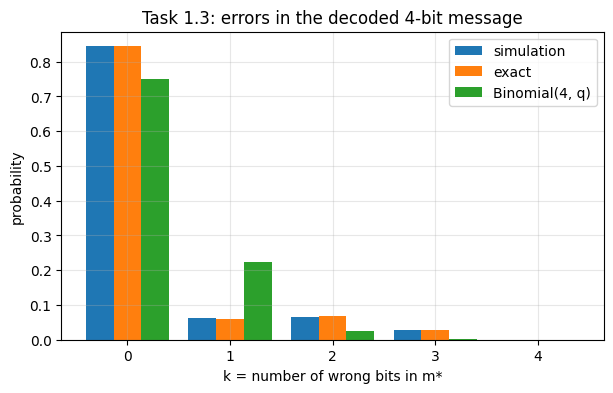

In [4]:
k = np.sum(m != m_star, axis=1)              # number of wrong bits in the decoded message
freq = np.bincount(k, minlength=5) / N

# exact distribution of K: the code is linear, so we may take m = 0000 (c = 0) and r = error pattern e
patterns = (np.arange(128)[:, None] >> np.arange(7)) & 1        # all 2^7 error patterns
zz = (patterns @ H) % 2
pos = zz[:, 0] + 2*zz[:, 1] + 4*zz[:, 2]
dec = patterns.copy()
bad = np.where(pos > 0)[0]
dec[bad, pos[bad] - 1] ^= 1
dec_msg = dec[:, [2, 4, 5, 6]]
K_pat = dec_msg.sum(axis=1)                  # wrong bits in the decoded message
w = patterns.sum(axis=1)                     # number of flipped bits
prob_pat = p**w * (1 - p)**(7 - w)
pmf_exact = np.array([prob_pat[K_pat == j].sum() for j in range(5)])
print("decoding is correct  <=>  at most one flipped bit:", bool(np.all((K_pat == 0) == (w <= 1))))

# best-fitting Binomial(4, q) (same mean)
q = pmf_exact @ np.arange(5) / 4
pmf_bin = binom.pmf(np.arange(5), 4, q)
exp_counts = N * pmf_bin
chi2 = np.sum((np.bincount(k, minlength=5) - exp_counts)**2 / exp_counts)
print(f"q = E[K]/4 = {q:.4f}")
print(" k | simulated | exact   | Binomial(4,q)")
for j in range(5):
    print(f" {j} | {freq[j]:.5f}   | {pmf_exact[j]:.5f} | {pmf_bin[j]:.5f}")
print(f"chi-square statistic vs Binomial(4,q): {chi2:.1f}  (df = 3, p-value = {stats.chi2.sf(chi2, 3):.2e})")

# are the four decoded bits independent?  exact pairwise check
qj = (prob_pat[:, None] * dec_msg).sum(axis=0)
print("P(bit j wrong):", np.round(qj, 4))
for i in range(4):
    for j in range(i + 1, 4):
        joint = (prob_pat * dec_msg[:, i] * dec_msg[:, j]).sum()
        print(f"P(bit {i+1} & bit {j+1} wrong) = {joint:.4f}   vs  product of marginals = {qj[i]*qj[j]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(5)
ax.bar(x - 0.27, freq, width=0.27, label="simulation")
ax.bar(x, pmf_exact, width=0.27, label="exact")
ax.bar(x + 0.27, pmf_bin, width=0.27, label="Binomial(4, q)")
ax.set_xticks(x); ax.set_xlabel("k = number of wrong bits in m*"); ax.set_ylabel("probability")
ax.set_title("Task 1.3: errors in the decoded 4-bit message"); ax.legend()
plt.show()

#### Task 1.3: number of wrong bits in the decoded message

Let $K\in\{0,1,2,3,4\}$ be the number of wrong bits in $m^*$. The histogram compares the simulation with the **exact** distribution. For the exact one I enumerate all $2^7$ error patterns; the code is linear, so the pattern of decoding errors does not depend on $m$ and one may take $m=0000$.

**Is $K$ a known distribution?** The natural candidate is $\mathrm{Bin}(4,q)$, which requires the four decoded bits to be wrong *independently* with the same probability $q$. The exact calculation shows:

* the marginals are identical: each decoded bit is wrong with probability $0.0697$ (so $q=0.0697$ is the best binomial candidate);
* the bits are **not independent**: every pair is wrong simultaneously with probability $0.0252$, five times the product of marginals $0.0697^2=0.0049$.

The reason is that a decoding failure (probability $1-p^*=0.156$, at least two channel errors) means the decoder outputs another codeword. Non-zero codewords have weight $3,4$ or $7$, so a failure typically damages several message bits at once: errors come in bursts.

Consequently $K$ is a mixture: $K=0$ with probability $p^*=0.844$, otherwise $K\ge1$ with conditional probabilities about $(0.39,\,0.43,\,0.18,\,10^{-4})$ for $k=1,\dots,4$. It is far from $\mathrm{Bin}(4,q)$: $P(K=1)=0.061$ vs $0.225$, $P(K=3)=0.028$ vs $0.0013$, $P(K=0)=0.844$ vs $0.749$. The $\chi^2$ statistic is $7.6\cdot10^4$ on 3 degrees of freedom ($p$-value $\approx 0$). It is not Poisson either (bounded support).

**Conclusion.** $K$ has no standard distribution. The simulated frequencies match the exact pmf to about three decimals, which also validates the code.

## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


In [5]:
M_Cs = 137.0                         # g/mol: molar mass of Cs-137
N_A = 6e23
T = 30.1 * 365.25 * 24 * 3600        # half-life in seconds
m_g = (10 + team_id) * 1e-14         # mass of one sample, in grams
N_atoms = m_g / M_Cs * N_A
lam = np.log(2) / T
mu = N_atoms * lam
print(f"m = {m_g:.2e} g,  atoms N = {N_atoms:.4e},  lambda = {lam:.4e} 1/s")
print(f"mu = N*lambda = {mu:.4f}")

m = 4.30e-13 g,  atoms N = 1.8832e+09,  lambda = 7.2972e-10 1/s
mu = N*lambda = 1.3742


#### Task 2.1: the Poisson parameter

Each $X_i$ is Poisson$(\mu)$ with $\mu=N\lambda$ (a huge number $N$ of atoms, each with a tiny decay probability $\lambda$ per second, which is the Poisson limit theorem). With $M(^{137}\mathrm{Cs}) = 137$ g/mol, $m = (10+33)\cdot10^{-14} = 4.3\cdot 10^{-13}$ g and $T = 30.1$ years $= 9.50\cdot10^{8}$ s:
$$N=\frac{m}{M}N_A = 1.883\cdot 10^{9},\qquad \lambda=\frac{\ln 2}{T}=7.297\cdot10^{-10}\ \mathrm{s^{-1}},\qquad \boxed{\mu = N\lambda = 1.3742 }.$$
So one sample produces on average about $1.37$ decays per second, and $EX_i=\mathrm{Var}X_i=\mu$.

 n | mean(s) | mu     | var(s)  | mu/n    | max diff | diff*sqrt(n) | half largest atom
 5 | 1.3757  | 1.3742 | 0.27706 | 0.27484 | 0.0893   | 0.200        | 0.0758
10 | 1.3719  | 1.3742 | 0.14052 | 0.13742 | 0.0704   | 0.223        | 0.0539
50 | 1.3743  | 1.3742 | 0.02722 | 0.02748 | 0.0286   | 0.202        | 0.0241


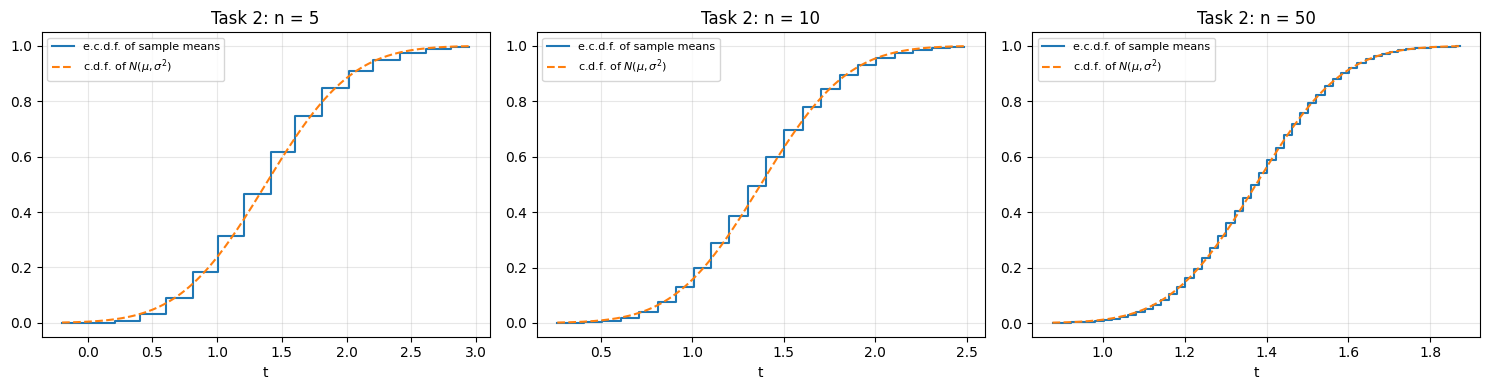

In [6]:
def ecdf_vs_normal(s, mu_n, sigma_n, ax, title):
    """plot e.c.d.f. of s and N(mu_n, sigma_n^2) c.d.f.; return the max difference on a 200-point grid"""
    Fs = ecdf(s).cdf.evaluate
    Fz = norm(mu_n, sigma_n).cdf
    t = np.linspace(mu_n - 3*sigma_n, mu_n + 3*sigma_n, 200)
    ax.step(t, Fs(t), where="post", label="e.c.d.f. of sample means")
    ax.plot(t, Fz(t), "--", label=r"c.d.f. of $N(\mu,\sigma^2)$")
    ax.set_title(title); ax.set_xlabel("t"); ax.legend(loc="upper left", fontsize=8)
    return np.max(np.abs(Fs(t) - Fz(t)))

K = 20000
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
print(" n | mean(s) | mu     | var(s)  | mu/n    | max diff | diff*sqrt(n) | half largest atom")
for ax, n in zip(axes, (5, 10, 50)):
    s = np.random.poisson(mu, size=(K, n)).mean(axis=1)
    sigma_n = np.sqrt(mu / n)
    d = ecdf_vs_normal(s, mu, sigma_n, ax, f"Task 2: n = {n}")
    half_jump = 0.5 * poisson.pmf(int(n*mu), n*mu)    # half of the largest atom of the exact distribution
    print(f"{n:2d} | {s.mean():.4f}  | {mu:.4f} | {s.var(ddof=1):.5f} | {mu/n:.5f} | {d:.4f}   | {d*np.sqrt(n):.3f}        | {half_jump:.4f}")
plt.tight_layout(); plt.show()

#### Task 2.2: sample means are approximately normal

**Theory.** The $X_i$ are i.i.d. with mean $\mu$ and variance $\mu$, so the CLT gives
$$\bar X_n \approx \mathcal N\!\Big(\mu,\ \frac{\mu}{n}\Big),\qquad \mu = 1.3742 .$$
(Indeed $n\bar X_n\sim\mathrm{Poisson}(n\mu)$ exactly.) I simulated $K=20000$ sample means for each $n$ and compared their e.c.d.f. with this normal c.d.f. on a grid of 200 points in $\mu\pm3\sigma$.

**Results.**

| $n$ | mean of $\mathbf s$ | variance of $\mathbf s$ | $\mu/n$ | max difference |
|---|---|---|---|---|
| 5 | 1.3757 | 0.2771 | 0.2748 | 0.0893 |
| 10 | 1.3719 | 0.1405 | 0.1374 | 0.0704 |
| 50 | 1.3743 | 0.0272 | 0.0275 | 0.0286 |

**Comments.**

* The sample moments agree with $\mu$ and $\mu/n$, and the e.c.d.f. approaches the normal c.d.f. as $n$ grows.
* The maximal difference decreases like $1/\sqrt n$ (the last column of the output, $\max\text{diff}\cdot\sqrt n\approx0.20$, is nearly constant), as predicted by the Berry-Esseen theorem.
* For a *discrete* distribution a large part of the error is unavoidable. $\bar X_n$ takes only the values $k/n$, so its c.d.f. jumps, while the normal c.d.f. is continuous. Half of the largest jump is $0.076,\ 0.054,\ 0.024$ for $n=5,10,50$, which already accounts for most of the observed differences. The rest is skewness plus Monte Carlo noise (the DKW bound for $K=20000$ is about $\pm 0.01$).

**Conclusion.** The normal approximation is rough for $n=5$ (error about $0.09$), acceptable for $n=10$ and good for $n=50$ (error about $0.03$).

mu = 1.3742
largest n with P(S<100) > 0.95:  exact (Poisson c.d.f.) = 61,  Monte Carlo = 61
bounds:  Markov n <= 3,  Chernoff n <= 56,  CLT n <= 61 (with continuity correction 61)
 n   | exact P(S<100) | simulated
  3  | 1.0000         | 1.0000
 56  | 0.9934         | 0.9936
 61  | 0.9535         | 0.9553
 62  | 0.9365         | 0.9358


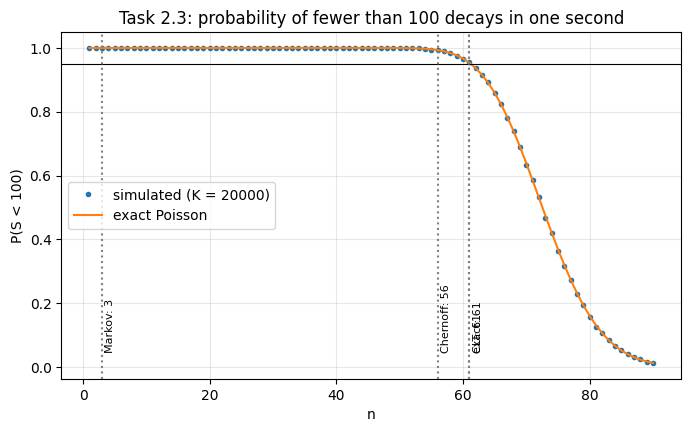

In [7]:
a = 100
nn = np.arange(1, 121)
mus = nn * mu                                           # parameter of S = X_1 + ... + X_n  ~  Poisson(n*mu)

exact = poisson.cdf(a - 1, mus)                         # P(S < a) = P(S <= 99)
n_exact = nn[exact > 0.95].max()

n_markov = int(np.floor(0.05 * a / mu))                 # P(S >= a) <= E[S]/a = n mu / a <= 0.05

log_chernoff = -mus + a * (1 + np.log(mus / a))         # log of exp(-n mu) (e n mu / a)^a, optimal t = ln(a/(n mu))
n_chernoff = nn[(mus < a) & (log_chernoff <= np.log(0.05))].max()

n_clt = nn[(a - mus) / np.sqrt(mus) >= z95].max()       # P(S < a) ~ Phi((a - n mu)/sqrt(n mu)) >= 0.95
n_clt_cc = nn[(a - 0.5 - mus) / np.sqrt(mus) >= z95].max()   # same with continuity correction

# Monte Carlo: simulate x_1..x_n, sum them, repeat K times
K = 20000
n_sim = np.arange(1, 91)
emp = np.array([(np.random.poisson(mu, size=(K, n)).sum(axis=1) < a).mean() for n in n_sim])
n_emp = n_sim[emp > 0.95].max()

print(f"mu = {mu:.4f}")
print(f"largest n with P(S<100) > 0.95:  exact (Poisson c.d.f.) = {n_exact},  Monte Carlo = {n_emp}")
print(f"bounds:  Markov n <= {n_markov},  Chernoff n <= {n_chernoff},  CLT n <= {n_clt} (with continuity correction {n_clt_cc})")
print(" n   | exact P(S<100) | simulated")
for n in sorted({n_markov, n_chernoff, n_clt, n_exact, n_exact + 1}):
    print(f"{n:3d}  | {exact[n-1]:.4f}         | {emp[n-1]:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(n_sim, emp, ".", label="simulated (K = 20000)")
ax.plot(nn[:90], exact[:90], "-", label="exact Poisson")
ax.axhline(0.95, color="k", lw=0.8)
for val, name in [(n_markov, "Markov"), (n_chernoff, "Chernoff"), (n_clt, "CLT"), (n_exact, "exact")]:
    ax.axvline(val, ls=":", color="gray"); ax.text(val + 0.5, 0.05, f"{name}: {val}", rotation=90, fontsize=8)
ax.set_xlabel("n"); ax.set_ylabel("P(S < 100)"); ax.set_title("Task 2.3: probability of fewer than 100 decays in one second")
ax.legend(loc="center left"); plt.show()

#### Task 2.3: how many samples may the laboratory accept?

$S=X_1+\dots+X_n\sim\mathrm{Poisson}(n\mu)$. We need the largest $n$ with $P(S<100)>0.95$, i.e. $P(S\ge100)<0.05$.

* **Markov:** $P(S\ge a)\le \dfrac{ES}{a}=\dfrac{n\mu}{100}\le0.05 \Rightarrow n\le \dfrac{5}{\mu}=3.64$, so $n=3$.
* **Chernoff:** $P(S\ge a)\le\inf_{t>0}e^{-ta}Ee^{tS}=\inf_{t>0}e^{-ta+n\mu(e^t-1)}$. The optimum is $t=\ln\frac{a}{n\mu}$ (valid for $n\mu<a$) and gives $e^{-n\mu}\big(\tfrac{e\,n\mu}{a}\big)^a\le0.05$, so $n\le 56$.
* **CLT:** $S\approx\mathcal N(n\mu,n\mu)$ gives $P(S<100)\approx\Phi\Big(\dfrac{100-n\mu}{\sqrt{n\mu}}\Big)\ge0.95\iff n\mu+1.645\sqrt{n\mu}\le100\iff n\mu\le 84.8$, so $n\le 61$ (also 61 with continuity correction).
* **Exact / Monte Carlo** ($K=20000$): the exact Poisson c.d.f. and the simulation both give $n=61$. Specifically $P(S<100)=0.9535$ (simulated $0.9553$) for $n=61$ and $0.9365$ (simulated $0.9358$) for $n=62$.

**Comparison.** Markov is extremely conservative (3 vs 61) because it uses only the mean. Chernoff uses the whole moment generating function and is much better (56) but still safe-side. The CLT answer (61) coincides with the exact one because $S$ is a sum of many terms and Poisson$(\approx 84)$ is nearly symmetric.

**Conclusion.** At most $\boxed{n=61}$ samples can be accepted. The Markov and Chernoff bounds are guaranteed but wasteful, while the CLT is accurate here but not a guarantee.

## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$

nu_1 = 4.3 min^-1,  E[X_i] = 1/nu_1 = 0.2326 min
 n | mean(s) | 1/nu1  | var(s)   | 1/(n nu1^2) | max diff | diff*sqrt(n)
 5 | 0.2331  | 0.2326 | 0.010888 | 0.010817    | 0.0584   | 0.131
10 | 0.2328  | 0.2326 | 0.005469 | 0.005408    | 0.0449   | 0.142
50 | 0.2327  | 0.2326 | 0.001103 | 0.001082    | 0.0257   | 0.182


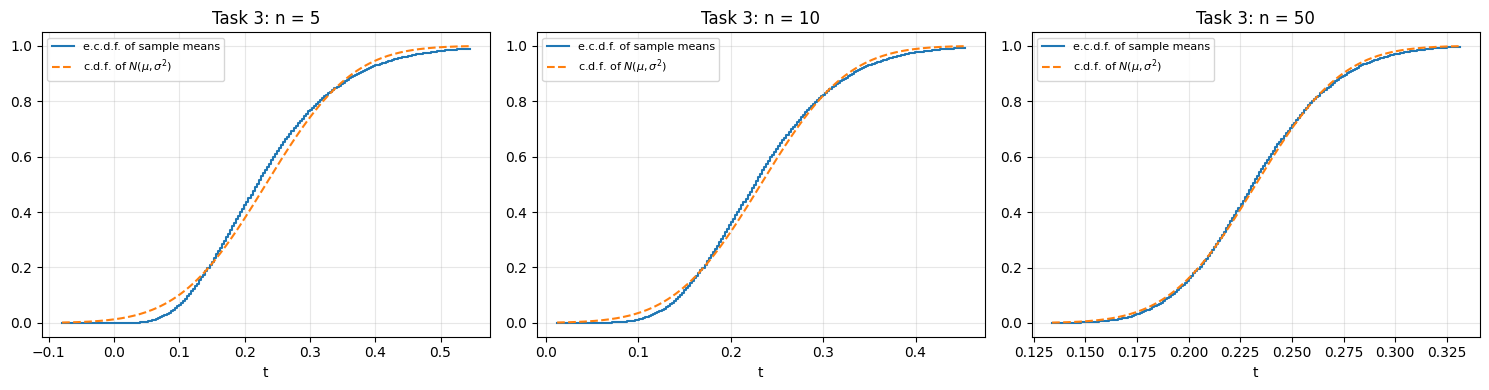

In [8]:
nu1 = team_id / 10 + 1
print("nu_1 =", nu1, "min^-1,  E[X_i] = 1/nu_1 =", round(1/nu1, 4), "min")

K = 20000
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
print(" n | mean(s) | 1/nu1  | var(s)   | 1/(n nu1^2) | max diff | diff*sqrt(n)")
for ax, n in zip(axes, (5, 10, 50)):
    s = np.random.exponential(scale=1/nu1, size=(K, n)).mean(axis=1)
    mu_n, sigma_n = 1/nu1, 1/(nu1*np.sqrt(n))
    d = ecdf_vs_normal(s, mu_n, sigma_n, ax, f"Task 3: n = {n}")
    print(f"{n:2d} | {s.mean():.4f}  | {mu_n:.4f} | {s.var(ddof=1):.6f} | {sigma_n**2:.6f}    | {d:.4f}   | {d*np.sqrt(n):.3f}")
plt.tight_layout(); plt.show()

#### Task 3.1: sample means of exponential waiting times

$X_i\sim\mathrm{Exp}(\nu_1)$ with $\nu_1=33/10+1=4.3\ \mathrm{min}^{-1}$, so $EX_i=1/\nu_1=0.2326$ min and $\mathrm{Var}X_i=1/\nu_1^2$. By the CLT
$$\bar X_n\approx\mathcal N\Big(\frac1{\nu_1},\ \frac{1}{n\nu_1^2}\Big).$$

| $n$ | mean of $\mathbf s$ | variance of $\mathbf s$ | $1/(n\nu_1^2)$ | max difference |
|---|---|---|---|---|
| 5 | 0.2331 | 0.010888 | 0.010817 | 0.0584 |
| 10 | 0.2328 | 0.005469 | 0.005408 | 0.0449 |
| 50 | 0.2327 | 0.001103 | 0.001082 | 0.0257 |

**Comments.** The sample moments match the theoretical ones, and the e.c.d.f. gets closer to the normal c.d.f. as $n$ grows. There is no lattice effect here, so the whole error comes from the skewness $\gamma=2$ of the exponential law. The first Edgeworth term predicts $\sup_x|F_n-\Phi|\approx\dfrac{\gamma}{6\sqrt n}\max_x|(x^2-1)\varphi(x)|=\dfrac{0.133}{\sqrt n}$, i.e. $0.060,\ 0.042,\ 0.019$. This matches the observed $0.058,\ 0.045,\ 0.026$ (for $n=50$ the difference is within the Monte Carlo noise of about $0.01$).

**Conclusion.** The normal approximation is already decent for $n=10$ and good for $n=50$. The skewed exponential law needs a few more terms than a symmetric one, and the error decays like $1/\sqrt n$.

check P(S>1) two ways for N = 19: 0.9726611969321305 0.9726611969321305
limits on nu:  Markov 4.950,  Chernoff 77.478,  CLT 83.551,  exact 84.139
=> limits on N = nu/nu_1:  1.15,  18.02,  19.43,  19.57
max N:  Markov 1,  Chernoff 18,  CLT 19,  exact 19
  N |   nu   | simulated P(safe) | exact P(safe)
  1 |   4.30 | 1.0000            | 1.0000
 18 |  77.40 | 0.9920            | 0.9923
 19 |  81.70 | 0.9715            | 0.9727
 20 |  86.00 | 0.9246            | 0.9247


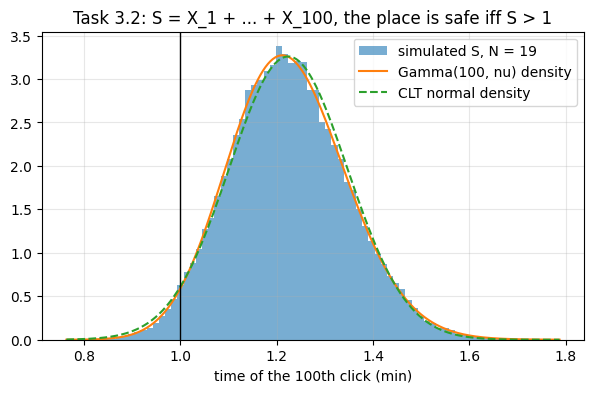

In [9]:
Ns = np.arange(1, 61)
nus = Ns * nu1                                           # nu = N nu_1,  S ~ Gamma(100, nu)
safe_exact = poisson.cdf(99, nus)                        # P(S > 1) = P(Poisson(nu) <= 99)
print("check P(S>1) two ways for N = 19:", gamma.sf(1, a=100, scale=1/(19*nu1)), poisson.cdf(99, 19*nu1))
N_exact = Ns[safe_exact >= 0.95].max()

# Markov for 1/S:  P(S <= 1) = P(1/S >= 1) <= E[1/S] = nu/99 <= 0.05
N_markov = Ns[nus / 99 <= 0.05].max()
# Chernoff:  P(S <= 1) <= min_t e^t (nu/(nu+t))^100 = (nu/100)^100 e^(100-nu)   (t* = 100 - nu)
log_ch = 100 * np.log(nus / 100) + (100 - nus)
N_chernoff = Ns[(nus < 100) & (log_ch <= np.log(0.05))].max()
# CLT:  S ~ N(100/nu, 100/nu^2),  P(S > 1) = Phi((100 - nu)/10) >= 0.95
nu_clt = 100 - 10 * z95
N_clt = Ns[(100 - nus) / 10 >= z95].max()

from scipy.optimize import brentq
nu_markov = 99 * 0.05
nu_chernoff = brentq(lambda v: 100*np.log(v/100) + (100 - v) - np.log(0.05), 50, 99)
nu_exact = brentq(lambda v: poisson.cdf(99, v) - 0.95, 50, 99)
print(f"limits on nu:  Markov {nu_markov:.3f},  Chernoff {nu_chernoff:.3f},  CLT {nu_clt:.3f},  exact {nu_exact:.3f}")
print(f"=> limits on N = nu/nu_1:  {nu_markov/nu1:.2f},  {nu_chernoff/nu1:.2f},  {nu_clt/nu1:.2f},  {nu_exact/nu1:.2f}")
print(f"max N:  Markov {N_markov},  Chernoff {N_chernoff},  CLT {N_clt},  exact {N_exact}")

# (c)-(e) simulation of S = X_1 + ... + X_100 with the predicted N
Kc = 50000
def prob_safe(N, Kc=Kc):
    S = np.random.exponential(scale=1/(N*nu1), size=(Kc, 100)).sum(axis=1)
    return (S > 1).mean(), S

print("  N |   nu   | simulated P(safe) | exact P(safe)")
for N in sorted({N_markov, N_chernoff, N_clt, N_exact, N_exact + 1}):
    ps, _ = prob_safe(N)
    print(f"{N:3d} | {N*nu1:6.2f} | {ps:.4f}            | {safe_exact[N-1]:.4f}")

ps, S = prob_safe(N_clt)
nu = N_clt * nu1
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(S, bins=80, density=True, alpha=0.6, label=f"simulated S, N = {N_clt}")
t = np.linspace(S.min(), S.max(), 400)
ax.plot(t, gamma.pdf(t, a=100, scale=1/nu), label="Gamma(100, nu) density")
ax.plot(t, norm.pdf(t, 100/nu, 10/nu), "--", label="CLT normal density")
ax.axvline(1, color="k", lw=1); ax.set_xlabel("time of the 100th click (min)")
ax.set_title("Task 3.2: S = X_1 + ... + X_100, the place is safe iff S > 1"); ax.legend(); plt.show()

#### Task 3.2: how many radioactive samples can be stored?

**(a) The event.** With $\nu=N\nu_1$ the waiting times are i.i.d. $\mathrm{Exp}(\nu)$, so $S=X_1+\dots+X_{100}\sim\mathrm{Gamma}(100,\nu)$ is the time of the 100th click. Fewer than 100 clicks in the first minute means the 100th click comes after time 1:
$$\text{safe}=\{S>1\},\qquad\text{need } P(S>1)\ge0.95\iff P(S\le1)\le0.05 .$$
Equivalently, the number of clicks in a minute is Poisson$(\nu)$ and we need $P(\mathrm{Poisson}(\nu)\le99)\ge0.95$. The code verifies that the two expressions coincide.

**(b) Bounds on $N$.**

* **Markov**, applied to the non-negative variable $1/S$: $P(S\le1)=P(1/S\ge1)\le E[1/S]=\dfrac{\nu}{99}$ (since $\int_0^\infty\frac1s\frac{\nu^{100}s^{99}e^{-\nu s}}{\Gamma(100)}ds=\frac{\nu\,\Gamma(99)}{\Gamma(100)}$). Hence $\nu\le4.95$, $N\le1.15$, so $N=1$.
* **Chernoff:** $P(S\le1)\le\inf_{t>0}e^{t}Ee^{-tS}=\inf_{t>0}e^t\Big(\dfrac{\nu}{\nu+t}\Big)^{100}$. The optimum is $t=100-\nu$ and gives $\Big(\dfrac{\nu}{100}\Big)^{100}e^{100-\nu}\le0.05$, i.e. $\nu\le77.48$, $N\le18.02$, so $N=18$.
* **CLT:** $S\approx\mathcal N(100/\nu,\,100/\nu^2)$, so $P(S>1)\approx\Phi\Big(\dfrac{100-\nu}{10}\Big)\ge0.95\iff\nu\le100-16.45=83.55$, $N\le19.43$, so $N=19$.
* **Exact:** $\nu\le84.14$, $N\le19.57$, so $N=19$.

**(c)-(e) Simulation.** For each predicted $N$ I simulated $K=50000$ values of $S=X_1+\dots+X_{100}$ and estimated $P(S>1)$:

| $N$ | $\nu$ | simulated $P(\text{safe})$ | exact |
|---|---|---|---|
| 1 (Markov) | 4.3 | 1.0000 | 1.0000 |
| 18 (Chernoff) | 77.4 | 0.9920 | 0.9923 |
| 19 (CLT) | 81.7 | 0.9715 | 0.9727 |
| 20 | 86.0 | 0.9246 | 0.9247 |

The histogram shows that the simulated $S$ follows both the Gamma density and its CLT normal approximation, with the threshold $S=1$ in the left tail.

**Conclusion.** The maximal number of samples is $\boxed{N=19}$: the place is judged safe with probability $0.972\ge0.95$, whereas $N=20$ gives only $0.925$. Markov (1) is useless in practice, Chernoff (18) is guaranteed and nearly sharp, and the CLT (19) gives the right answer here because $S$ has 100 terms.

## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


#### Task 4, part 1(a): why $E(1/X)\neq 1/E(X)$

Expectation commutes only with *linear* maps: $E(aX+b)=aEX+b$. The map $x\mapsto1/x$ is not linear, so there is no reason for $E(1/X)$ and $1/E(X)$ to agree. For $X>0$ non-degenerate, $x\mapsto 1/x$ is strictly convex and Jensen's inequality gives $E(1/X)>1/E(X)$. Example: $X\in\{1,3\}$ with probability $\tfrac12$ each gives $E(1/X)=\tfrac12(1+\tfrac13)=\tfrac23>\tfrac12=1/EX$. If $X$ can take values near $0$ or of both signs, $E(1/X)$ may not even exist.

1/mean(x) = 0.2308,   mean(1/x) = -0.4604
negative x: 7,   smallest |x| = 0.0251,   largest |1/x| = 39.90
quantiles (0, 5%, 50%, 95%, 100%) over 2000 repetitions
  1/mean(x): [0.161 0.181 0.2   0.223 0.27 ]
  mean(1/x): [-72.397  -0.385   0.234   1.157 139.671]
P(X<0) = 0.0569


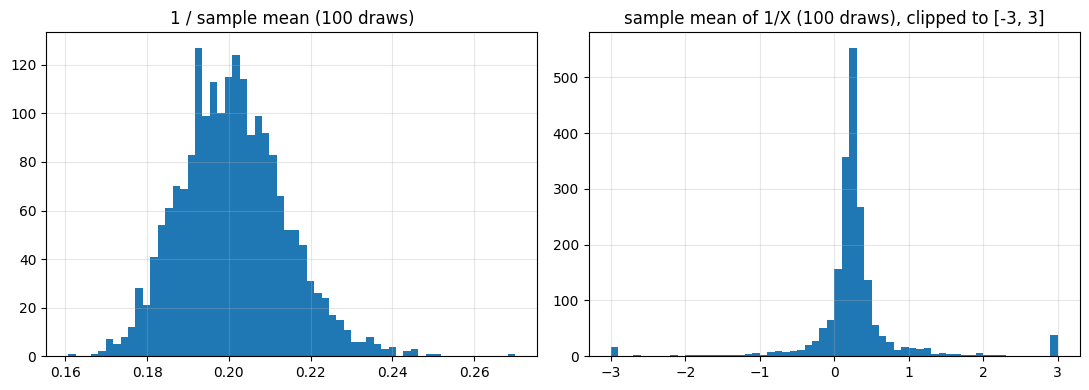

In [10]:
x = np.random.normal(5, np.sqrt(10), size=100)
y = 1 / x
print(f"1/mean(x) = {1/x.mean():.4f},   mean(1/x) = {y.mean():.4f}")
print(f"negative x: {(x < 0).sum()},   smallest |x| = {np.abs(x).min():.4f},   largest |1/x| = {np.abs(y).max():.2f}")

reps = 2000
xs = np.random.normal(5, np.sqrt(10), size=(reps, 100))
inv_of_mean = 1 / xs.mean(axis=1)
mean_of_inv = (1 / xs).mean(axis=1)
qs = [0, 0.05, 0.5, 0.95, 1]
print("quantiles (0, 5%, 50%, 95%, 100%) over", reps, "repetitions")
print("  1/mean(x):", np.round(np.quantile(inv_of_mean, qs), 3))
print("  mean(1/x):", np.round(np.quantile(mean_of_inv, qs), 3))
print("P(X<0) =", round(norm.cdf(0, 5, np.sqrt(10)), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(inv_of_mean, bins=60); axes[0].set_title("1 / sample mean (100 draws)")
axes[1].hist(np.clip(mean_of_inv, -3, 3), bins=60); axes[1].set_title("sample mean of 1/X (100 draws), clipped to [-3, 3]")
plt.tight_layout(); plt.show()

#### Task 4, part 1(b): $1/\bar X$ versus $\bar Y$ for $X\sim\mathcal N(5,10)$

**Results (100 draws).** $1/\bar x=0.2308$ is close to $1/EX=0.2$, but $\bar y=-0.4604$ is not even positive. Seven of the 100 draws are negative ($P(X<0)=0.057$), and the smallest $|x|=0.025$ gives $y=39.9$ alone.

**Explanation.** $X$ has a positive density at $0$, so $E|1/X|=\int\frac{1}{|x|}f(x)\,dx$ diverges like $\int dx/|x|$: **$E(1/X)$ does not exist**, and the law of large numbers does not apply to $\bar Y$. By contrast $\bar X\to5$, and by continuity of $x\mapsto 1/x$ at $5$ we get $1/\bar X\to0.2$.

**Repetition ($2000$ experiments of 100 draws).** $1/\bar X$ is very stable (5%-95% range $0.181$-$0.223$). $\bar Y$ is wildly variable: the 5%-95% range is $-0.39$ to $1.16$, but extremes reach $-72$ and $+140$. This is heavy-tailed behaviour, where a single value near $0$ dominates the mean.

**Conclusion.** $1/\bar X\ne\bar Y$, and the second quantity is meaningless as an estimate of anything: "the expectation of the inverse" is not "the inverse of the expectation", and sometimes it does not exist at all.

corr(X,Y) = -0.081,  Spearman(X,Y) = -0.046
corr(X,Z) = 0.775,  Spearman(X,Z) = 1.000
two-sample KS test, X vs Y: p-value = 0.648
two-sample KS test, X vs Z: p-value = 0.00e+00


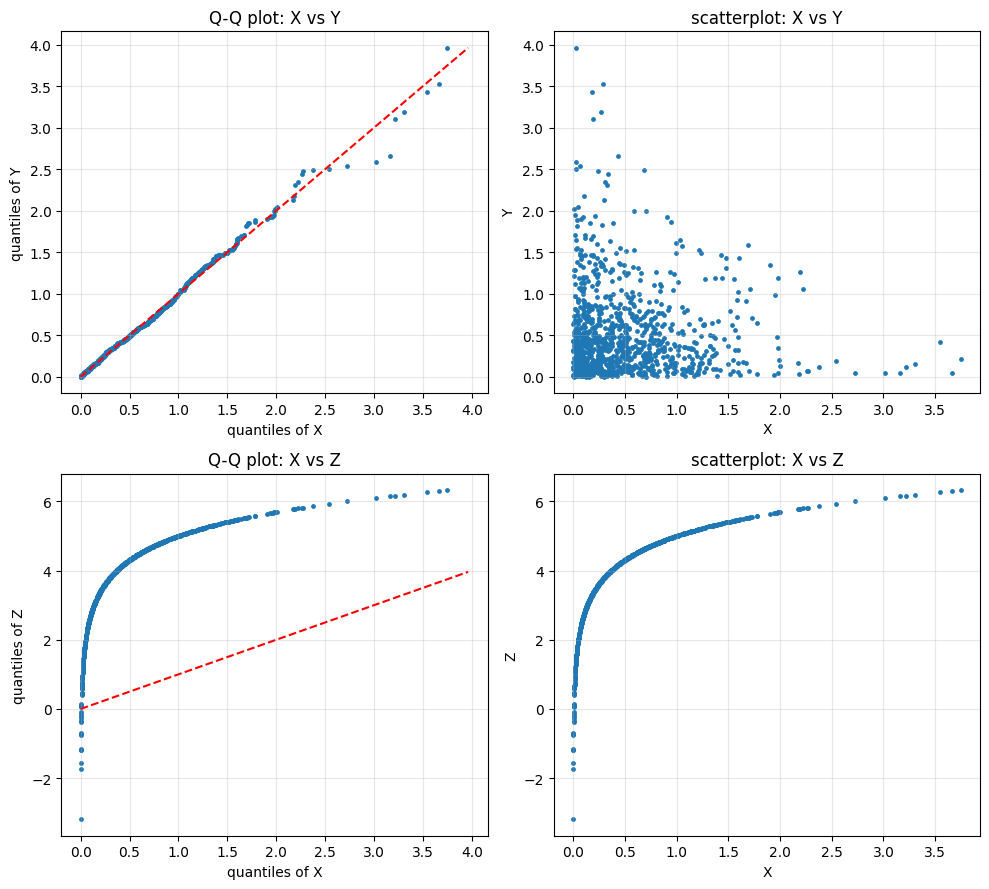

In [11]:
n = 1000
x = np.random.exponential(scale=1/2, size=n)
y = np.random.exponential(scale=1/2, size=n)
z = np.log(x) + 5

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
lim = max(x.max(), y.max())
axes[0, 0].scatter(np.sort(x), np.sort(y), s=6); axes[0, 0].plot([0, lim], [0, lim], "r--")
axes[0, 0].set_title("Q-Q plot: X vs Y"); axes[0, 0].set_xlabel("quantiles of X"); axes[0, 0].set_ylabel("quantiles of Y")
axes[0, 1].scatter(x, y, s=6); axes[0, 1].set_title("scatterplot: X vs Y"); axes[0, 1].set_xlabel("X"); axes[0, 1].set_ylabel("Y")
axes[1, 0].scatter(np.sort(x), np.sort(z), s=6); axes[1, 0].plot([0, lim], [0, lim], "r--")
axes[1, 0].set_title("Q-Q plot: X vs Z"); axes[1, 0].set_xlabel("quantiles of X"); axes[1, 0].set_ylabel("quantiles of Z")
axes[1, 1].scatter(x, z, s=6); axes[1, 1].set_title("scatterplot: X vs Z"); axes[1, 1].set_xlabel("X"); axes[1, 1].set_ylabel("Z")
plt.tight_layout(); plt.show()

print(f"corr(X,Y) = {np.corrcoef(x, y)[0, 1]:.3f},  Spearman(X,Y) = {stats.spearmanr(x, y)[0]:.3f}")
print(f"corr(X,Z) = {np.corrcoef(x, z)[0, 1]:.3f},  Spearman(X,Z) = {stats.spearmanr(x, z)[0]:.3f}")
print(f"two-sample KS test, X vs Y: p-value = {stats.ks_2samp(x, y).pvalue:.3f}")
print(f"two-sample KS test, X vs Z: p-value = {stats.ks_2samp(x, z).pvalue:.2e}")

#### Task 4, part 1(c): $X,Y$ i.i.d. $\mathrm{Exp}(2)$ and $Z=\ln X+5$

**$X$ vs $Y$.** They are independent and identically distributed. The Q-Q plot hugs the diagonal (scatter appears only in the far tail, where order statistics are noisy), and the two-sample Kolmogorov-Smirnov test gives $p=0.65$. The scatterplot is a structureless cloud over the positive quadrant. The sample correlations are small ($-0.08$ Pearson, $-0.05$ Spearman, the latter within the $\pm0.06$ expected by chance for $n=1000$).

**$X$ vs $Z$.** $Z$ is a deterministic, strictly increasing function of $X$, so the pair is completely dependent: the scatterplot is exactly the curve $z=\ln x+5$. Because the map is increasing, the sorted $Z$-values equal $\ln(\text{sorted }x)+5$, so the Q-Q plot coincides with this curve and is far from the diagonal. The distributions differ ($Z$ lives on all of $\mathbb R$, is left-skewed and has mean $5-\gamma_E-\ln2\approx3.73$ against $0.5$ for $X$; KS $p\approx0$). The Pearson correlation is $0.775<1$ because the relation is non-linear, while Spearman is exactly $1$ because it is monotone.

**Conclusion.** $(X,Y)$ is independent and identically distributed. $(X,Z)$ is **dependent** and **not identically distributed**. The two properties are logically unrelated: dependence is about the joint law, identical distribution about the marginals.

#### Task 4, part 2: the coin game

**(a)** $X$ counts successes in $3$ independent trials with probability $\frac12$ each, so $X\sim\mathrm{Binomial}(3,\tfrac12)$, with pmf $(\tfrac18,\tfrac38,\tfrac38,\tfrac18)$. It is not normal (finite support), not Poisson (bounded by $3$) and not uniform.

In [12]:
# exact values
xv = np.arange(4); px = binom.pmf(xv, 3, 0.5)
EX = round((xv * px).sum(), 10);  VarX = round(((xv - EX)**2 * px).sum(), 10)
yv = xv**2
EY = round((yv * px).sum(), 10);  VarY = round((yv**2 * px).sum() - EY**2, 10)
print(f"pmf of X: {px},   E X = {EX},  Var X = {VarX}")
print(f"E(Y) = {EY},  Var(Y) = {VarY},  (E X)^2 = {EX**2},  E(X^2) - (E X)^2 = {round(EY - EX**2, 10)}")
print(f"expected net gain per round = E(Y) - 3 = {round(EY - 3, 10)}")

# simulation of 100 rounds
x = np.random.binomial(3, 0.5, size=100)
y = x**2
print(f"\nsample of X:  mean = {x.mean():.3f},  s^2 = {x.var(ddof=1):.3f}")
print(f"sample of Y:  mean = {y.mean():.3f},  s^2 = {y.var(ddof=1):.3f}")
eps = z975 * y.std(ddof=1) / np.sqrt(100)
print(f"95% CI for E(Y): {y.mean():.3f} +- {eps:.3f} = ({y.mean()-eps:.3f}, {y.mean()+eps:.3f}),  contains 3: {y.mean()-eps < 3 < y.mean()+eps}")

# how many rounds to separate E(Y) = 3 from a game whose mean payoff is 2.9?
sigma_Y = np.sqrt(VarY)
n_eps = int(np.ceil((z975 * sigma_Y / 0.1)**2))                          # eps <= 0.1 (the gap)
n_80 = int(np.ceil(((z975 + norm.ppf(0.8)) * sigma_Y / 0.1)**2))         # 80% probability the CI excludes 2.9
print(f"\nrounds with eps <= 0.1: {n_eps};   rounds for 80% chance to exclude 2.9: {n_80}")

def power(n, reps=2000):
    yy = np.random.binomial(3, 0.5, size=(reps, n))**2
    return np.mean(yy.mean(axis=1) - z975 * yy.std(axis=1, ddof=1) / np.sqrt(n) > 2.9)
for n in (100, n_eps, n_80):
    print(f"n = {n:5d}: fraction of experiments whose 95% CI excludes 2.9 (true mean 3) = {power(n):.3f}")

pmf of X: [0.125 0.375 0.375 0.125],   E X = 1.5,  Var X = 0.75
E(Y) = 3.0,  Var(Y) = 7.5,  (E X)^2 = 2.25,  E(X^2) - (E X)^2 = 0.75
expected net gain per round = E(Y) - 3 = 0.0

sample of X:  mean = 1.460,  s^2 = 0.796
sample of Y:  mean = 2.920,  s^2 = 7.913
95% CI for E(Y): 2.920 +- 0.551 = (2.369, 3.471),  contains 3: True

rounds with eps <= 0.1: 2882;   rounds for 80% chance to exclude 2.9: 5887
n =   100: fraction of experiments whose 95% CI excludes 2.9 (true mean 3) = 0.042
n =  2882: fraction of experiments whose 95% CI excludes 2.9 (true mean 3) = 0.483
n =  5887: fraction of experiments whose 95% CI excludes 2.9 (true mean 3) = 0.803


**(b)** $EX=np=1.5$ and $\mathrm{Var}X=np(1-p)=0.75$. The simulation of 100 rounds gives $\bar x=1.460$ and $s^2=0.796$. Both are close to the exact values (the standard error of $\bar x$ is $\sqrt{0.75/100}=0.087$, so the deviation is about half a standard error).

**(c)** The friend's argument is wrong, and it is the same mistake as in 1(a): he computes $g(EX)=(EX)^2=2.25$ instead of $E\,g(X)=E(X^2)$. Since $x\mapsto x^2$ is convex, $E(X^2)\ge(EX)^2$, and the gap is exactly the variance:
$$E(Y)=E(X^2)=\mathrm{Var}X+(EX)^2=0.75+2.25=3 .$$
Direct check: $Y\in\{0,1,4,9\}$ with probabilities $\tfrac18,\tfrac38,\tfrac38,\tfrac18$ gives $EY=\tfrac{0+3+12+9}{8}=3$. The entry fee is £3, so the expected net gain is $0$ and **the game is fair**. The variance is
$$\mathrm{Var}(Y)=E(X^4)-(EY)^2=\tfrac{0+3\cdot1+3\cdot16+81}{8}-9=16.5-9=7.5,\qquad \mathrm{sd}(Y)=2.74 .$$
The simulation gives $\bar y=2.920$ and $s^2=7.913$, close to $3$ and $7.5$. The deviation $0.08$ is far below the standard error $\approx0.27$, so it is no evidence of unfairness.

**(d)** By the CLT, the 95% confidence interval for $E(Y)$ from 100 rounds is $\bar y\pm1.96\,s/\sqrt{100}=2.920\pm0.551=(2.369,\,3.471)$. It contains $3$, but it also contains $2.9$, $2.5$ and $3.4$, so **the simulation alone cannot tell whether the game is fair**: the half-length $0.55$ is much larger than the differences we care about, and a finite simulation can never prove an exact equality anyway. To tell the fair game from one with mean payoff $2.9$ (a gap of $0.1$) we need $\varepsilon\le 0.1$:
$$n\ge\Big(\frac{1.96\,\sigma_Y}{0.1}\Big)^2=\Big(\frac{1.96\cdot 2.739}{0.1}\Big)^2\approx 2882\ \text{rounds}.$$
This is only the break-even point: the simulation shows that with $n=2882$ the interval excludes $2.9$ in just $48\%$ of experiments. For an $80\%$ chance, $n\ge\big((1.96+0.84)\sigma_Y/0.1\big)^2\approx5887$ rounds (observed $0.803$). With the original $100$ rounds the chance is only $4\%$.

**Conclusion.** The game is fair and $\mathrm{Var}(Y)=7.5$. Telling nearly-fair games apart by simulation costs thousands of rounds because the error shrinks only like $1/\sqrt n$.

## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.